LOGISTIC REGRESSION: Risk_Level ~ TOWN + Duration_hours + AVG_NOISE_LVL + LATITUDE
Data Split: 80% Train (5889 rows) | 20% Test (1473 rows)
Train Accuracy: 99.37% | Test Accuracy: 99.39%

Classification Report (Test Set):
              precision    recall  f1-score   support

     Low (1)       1.00      0.97      0.99       193
  Medium (2)       0.99      1.00      0.99       698
    High (3)       1.00      1.00      1.00       582

    accuracy                           0.99      1473
   macro avg       1.00      0.99      0.99      1473
weighted avg       0.99      0.99      0.99      1473

Custom Scenario 1: TOWN=Boleslawiec, Noise=55.0dB, Duration=2.0h, Lat=51.2558
  --> Predicted Risk Level: 1 | Class Probabilities: [0.577 0.423 0.   ]
Custom Scenario 2: TOWN=Boleslawiec, Noise=88.0dB, Duration=9.0h, Lat=51.2558
  --> Predicted Risk Level: 3 | Class Probabilities: [0. 0. 1.]


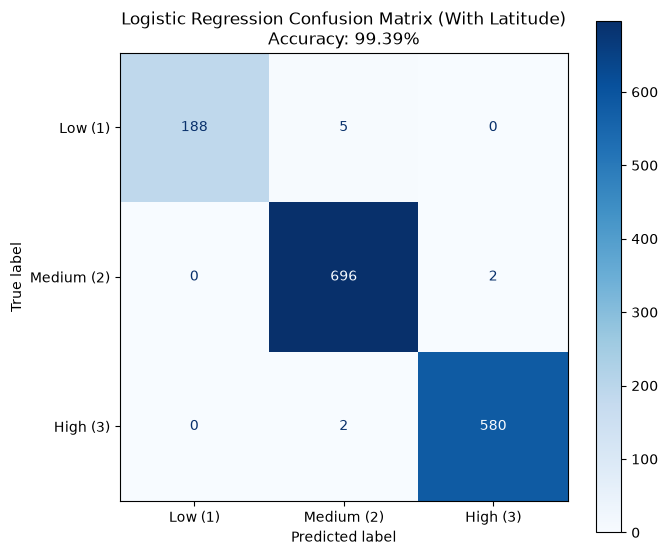

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ==========================================================
# Load Excel File
# ==========================================================
file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(file_path, sheet_name="Road_noise_measurements")

df.columns = [c.strip() for c in df.columns]

# ==========================================================
# Universal Risk_Level Parser (Target: 1, 2, 3)
# ==========================================================
def parse_risk(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower().replace(".0", "")
    mapping = {
        "1": 1, "low": 1, "l": 1,
        "2": 2, "medium": 2, "med": 2, "moderate": 2, "m": 2,
        "3": 3, "high": 3, "h": 3, "severe": 3
    }
    return mapping.get(s, np.nan)

df["Risk_Level"] = df["Risk_Level"].apply(parse_risk)

# Convert numeric feature columns (including LATITUDE)
numeric_features = ["AVG_NOISE_LVL", "Duration_hours", "LATITUDE"]
for col in numeric_features:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(",", ".", regex=False)
            .str.replace(r"[^\d.-]", "", regex=True)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Clean categorical TOWN column
df["TOWN"] = df["TOWN"].astype(str).str.strip()

# Keep only rows where target and all features are valid
feature_cols = ["TOWN", "Duration_hours", "AVG_NOISE_LVL", "LATITUDE"]
data = df[feature_cols + ["Risk_Level"]].dropna().copy()
data["Risk_Level"] = data["Risk_Level"].astype(int)

# ==========================================================
# Feature Encoding & Train/Test Split (80% Train, 20% Test)
# ==========================================================
X_encoded = pd.get_dummies(data[feature_cols], columns=["TOWN"], drop_first=True)
y = data["Risk_Level"]

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

# Scale numeric features for stable gradient convergence
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

# ==========================================================
# Train Logistic Regression Model
# ==========================================================
log_reg = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)
log_reg.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = log_reg.predict(X_train_scaled)
y_test_pred = log_reg.predict(X_test_scaled)
y_test_proba = log_reg.predict_proba(X_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred) * 100
test_acc = accuracy_score(y_test, y_test_pred) * 100

print("=" * 70)
print("LOGISTIC REGRESSION: Risk_Level ~ TOWN + Duration_hours + AVG_NOISE_LVL + LATITUDE")
print("=" * 70)
print(f"Data Split: 80% Train ({len(X_train)} rows) | 20% Test ({len(X_test)} rows)")
print(f"Train Accuracy: {train_acc:.2f}% | Test Accuracy: {test_acc:.2f}%\n")
print("Classification Report (Test Set):")

unique_labels = sorted(y.unique())
target_names_dict = {1: "Low (1)", 2: "Medium (2)", 3: "High (3)"}
present_names = [target_names_dict[cls] for cls in unique_labels]

print(classification_report(y_test, y_test_pred, labels=unique_labels, target_names=present_names))

# ==========================================================
# Custom Sample Predictions
# ==========================================================
custom_samples = pd.DataFrame([
    {
        "TOWN": data["TOWN"].iloc[0],
        "AVG_NOISE_LVL": 55.0,
        "Duration_hours": 2.0,
        "LATITUDE": data["LATITUDE"].iloc[0]
    },
    {
        "TOWN": data["TOWN"].iloc[0],
        "AVG_NOISE_LVL": 88.0,
        "Duration_hours": 9.0,
        "LATITUDE": data["LATITUDE"].iloc[0]
    }
])

custom_encoded = pd.get_dummies(custom_samples, columns=["TOWN"])
custom_encoded = custom_encoded.reindex(columns=X_train.columns, fill_value=0)
custom_encoded[numeric_features] = scaler.transform(custom_encoded[numeric_features])

custom_preds = log_reg.predict(custom_encoded)
custom_probs = log_reg.predict_proba(custom_encoded)

print("=" * 70)
for idx, row in custom_samples.iterrows():
    pred_cls = custom_preds[idx]
    probs = custom_probs[idx]
    print(f"Custom Scenario {idx+1}: TOWN={row['TOWN']}, Noise={row['AVG_NOISE_LVL']}dB, Duration={row['Duration_hours']}h, Lat={row['LATITUDE']}")
    print(f"  --> Predicted Risk Level: {pred_cls} | Class Probabilities: {np.round(probs, 3)}")
print("=" * 70)

# ==========================================================
# Visual Plot: Confusion Matrix
# ==========================================================
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_test_pred, labels=log_reg.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=present_names)
disp.plot(cmap="Blues", ax=ax, values_format="d")

plt.title(f"Logistic Regression Confusion Matrix (With Latitude)\nAccuracy: {test_acc:.2f}%")
plt.grid(False)
plt.tight_layout()
plt.savefig("LogisticRegression_Risk_Level_With_Latitude_CM.png", dpi=300)
plt.show()

LOGISTIC REGRESSION: Risk_Level ~ TOWN + Duration_hours + AVG_NOISE_LVL + LATITUDE
Total Valid Rows: 6778
Data Split: 80% Train (5422 rows) | 20% Test (1356 rows)
Train Accuracy: 99.35% | Test Accuracy: 99.34%

Classification Report (Test Set):
              precision    recall  f1-score   support

     Low (1)       0.99      0.97      0.98       122
Moderate (2)       0.99      1.00      0.99       667
    High (3)       1.00      0.99      1.00       567

    accuracy                           0.99      1356
   macro avg       0.99      0.99      0.99      1356
weighted avg       0.99      0.99      0.99      1356

Custom Scenario 1: TOWN=Boleslawiec, Noise=55.0dB, Duration=8.0h, Lat=51.2558
  --> Predicted Risk Level: Low (1) | Probabilities [Low, Moderate, High]: [0.534 0.466 0.   ]
Custom Scenario 2: TOWN=Boleslawiec, Noise=68.0dB, Duration=16.0h, Lat=51.2558
  --> Predicted Risk Level: High (3) | Probabilities [Low, Moderate, High]: [0. 0. 1.]


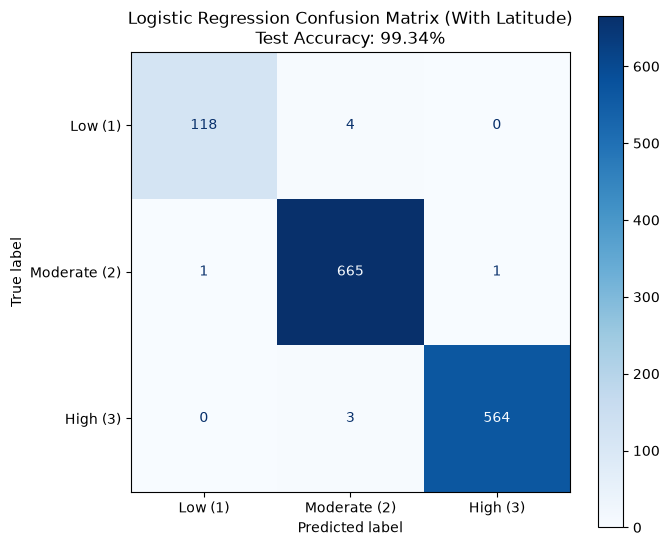

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ==========================================================
# Load Excel File
# ==========================================================
file_path = r"road_noise_no_blank_towns_no_outliers.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet")

df.columns = [c.strip() for c in df.columns]

# ==========================================================
# Universal Risk_Level Parser (Target: 1, 2, 3)
# ==========================================================
def parse_risk(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower().replace(".0", "")
    mapping = {
        "1": 1, "low": 1, "l": 1,
        "2": 2, "medium": 2, "med": 2, "moderate": 2, "m": 2,
        "3": 3, "high": 3, "h": 3, "severe": 3
    }
    return mapping.get(s, np.nan)

df["Risk_Level"] = df["Risk_Level"].apply(parse_risk)

# Convert numeric feature columns
numeric_features = ["AVG_NOISE_LVL", "Duration_hours", "LATITUDE"]
for col in numeric_features:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(",", ".", regex=False)
            .str.replace(r"[^\d.-]", "", regex=True)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Clean categorical TOWN column
df["TOWN"] = df["TOWN"].astype(str).str.strip()

# Keep only rows where target and all features are valid
feature_cols = ["TOWN", "Duration_hours", "AVG_NOISE_LVL", "LATITUDE"]
data = df[feature_cols + ["Risk_Level"]].dropna().copy()
data["Risk_Level"] = data["Risk_Level"].astype(int)

# ==========================================================
# Feature Encoding & Train/Test Split (80% Train, 20% Test)
# ==========================================================
X_encoded = pd.get_dummies(data[feature_cols], columns=["TOWN"], drop_first=True)
y = data["Risk_Level"]

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

# Scale numeric features for stable gradient convergence
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

# ==========================================================
# Train Logistic Regression Model
# ==========================================================
log_reg = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)
log_reg.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = log_reg.predict(X_train_scaled)
y_test_pred = log_reg.predict(X_test_scaled)
y_test_proba = log_reg.predict_proba(X_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred) * 100
test_acc = accuracy_score(y_test, y_test_pred) * 100

print("=" * 70)
print("LOGISTIC REGRESSION: Risk_Level ~ TOWN + Duration_hours + AVG_NOISE_LVL + LATITUDE")
print("=" * 70)
print(f"Total Valid Rows: {len(data)}")
print(f"Data Split: 80% Train ({len(X_train)} rows) | 20% Test ({len(X_test)} rows)")
print(f"Train Accuracy: {train_acc:.2f}% | Test Accuracy: {test_acc:.2f}%\n")
print("Classification Report (Test Set):")

unique_labels = sorted(y.unique())
target_names_dict = {1: "Low (1)", 2: "Moderate (2)", 3: "High (3)"}
present_names = [target_names_dict[cls] for cls in unique_labels]

print(classification_report(y_test, y_test_pred, labels=unique_labels, target_names=present_names))

# ==========================================================
# Custom Sample Predictions
# ==========================================================
custom_samples = pd.DataFrame([
    {
        "TOWN": data["TOWN"].iloc[0],
        "AVG_NOISE_LVL": 55.0,
        "Duration_hours": 8.0,
        "LATITUDE": data["LATITUDE"].iloc[0]
    },
    {
        "TOWN": data["TOWN"].iloc[0],
        "AVG_NOISE_LVL": 68.0,
        "Duration_hours": 16.0,
        "LATITUDE": data["LATITUDE"].iloc[0]
    }
])

custom_encoded = pd.get_dummies(custom_samples, columns=["TOWN"])
custom_encoded = custom_encoded.reindex(columns=X_train.columns, fill_value=0)
custom_encoded[numeric_features] = scaler.transform(custom_encoded[numeric_features])

custom_preds = log_reg.predict(custom_encoded)
custom_probs = log_reg.predict_proba(custom_encoded)

print("=" * 70)
for idx, row in custom_samples.iterrows():
    pred_cls = custom_preds[idx]
    probs = custom_probs[idx]
    print(f"Custom Scenario {idx+1}: TOWN={row['TOWN']}, Noise={row['AVG_NOISE_LVL']}dB, Duration={row['Duration_hours']}h, Lat={row['LATITUDE']}")
    print(f"  --> Predicted Risk Level: {target_names_dict[pred_cls]} | Probabilities [Low, Moderate, High]: {np.round(probs, 3)}")
print("=" * 70)

# ==========================================================
# Visual Plot: Confusion Matrix
# ==========================================================
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_test_pred, labels=log_reg.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=present_names)
disp.plot(cmap="Blues", ax=ax, values_format="d")

plt.title(f"Logistic Regression Confusion Matrix (With Latitude)\nTest Accuracy: {test_acc:.2f}%")
plt.grid(False)
plt.tight_layout()
plt.savefig("LogisticRegression_Risk_Level_Cleaned_Data_CM.png", dpi=300)
plt.show()

LOGISTIC REGRESSION: Risk_Level ~ TOWN + Duration_hours + AVG_NOISE_LVL + LATITUDE
Total Valid Rows: 6850
Data Split: 80% Train (5480 rows) | 20% Test (1370 rows)
Train Accuracy: 99.31% | Test Accuracy: 98.69%

Classification Report (Test Set):
              precision    recall  f1-score   support

     Low (1)       0.99      0.93      0.96       137
Moderate (2)       0.98      1.00      0.99       667
    High (3)       1.00      0.99      0.99       566

    accuracy                           0.99      1370
   macro avg       0.99      0.97      0.98      1370
weighted avg       0.99      0.99      0.99      1370

Custom Scenario 1: TOWN=Boleslawiec, Noise=55.0dB, Duration=8.0h, Lat=51.2558
  --> Predicted Risk Level: Low (1) | Probabilities [Low, Moderate, High]: [0.52 0.48 0.  ]
Custom Scenario 2: TOWN=Boleslawiec, Noise=68.0dB, Duration=16.0h, Lat=51.2558
  --> Predicted Risk Level: High (3) | Probabilities [Low, Moderate, High]: [0. 0. 1.]


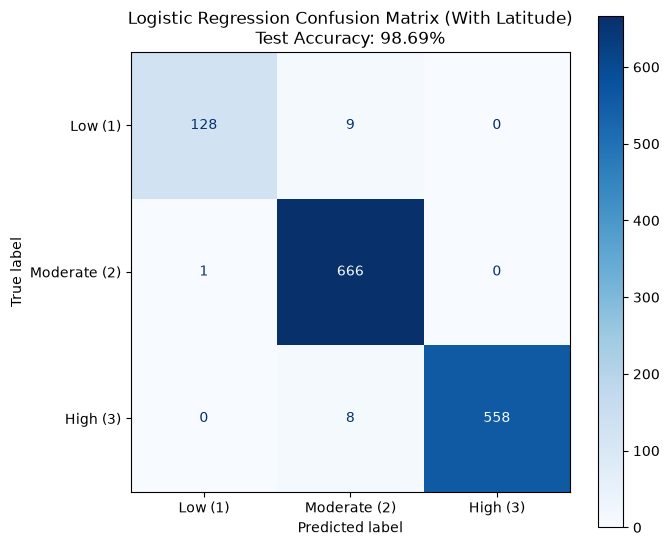

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ==========================================================
# Load Excel File
# ==========================================================
file_path = r"road_noise_no_blank_towns.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet")

df.columns = [c.strip() for c in df.columns]

# ==========================================================
# Universal Risk_Level Parser (Target: 1, 2, 3)
# ==========================================================
def parse_risk(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower().replace(".0", "")
    mapping = {
        "1": 1, "low": 1, "l": 1,
        "2": 2, "medium": 2, "med": 2, "moderate": 2, "m": 2,
        "3": 3, "high": 3, "h": 3, "severe": 3
    }
    return mapping.get(s, np.nan)

df["Risk_Level"] = df["Risk_Level"].apply(parse_risk)

# Convert numeric feature columns
numeric_features = ["AVG_NOISE_LVL", "Duration_hours", "LATITUDE"]
for col in numeric_features:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(",", ".", regex=False)
            .str.replace(r"[^\d.-]", "", regex=True)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Clean categorical TOWN column
df["TOWN"] = df["TOWN"].astype(str).str.strip()

# Keep only rows where target and all features are valid
feature_cols = ["TOWN", "Duration_hours", "AVG_NOISE_LVL", "LATITUDE"]
data = df[feature_cols + ["Risk_Level"]].dropna().copy()
data["Risk_Level"] = data["Risk_Level"].astype(int)

# ==========================================================
# Feature Encoding & Train/Test Split (80% Train, 20% Test)
# ==========================================================
X_encoded = pd.get_dummies(data[feature_cols], columns=["TOWN"], drop_first=True)
y = data["Risk_Level"]

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

# Scale numeric features for stable gradient convergence
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

# ==========================================================
# Train Logistic Regression Model
# ==========================================================
log_reg = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)
log_reg.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = log_reg.predict(X_train_scaled)
y_test_pred = log_reg.predict(X_test_scaled)
y_test_proba = log_reg.predict_proba(X_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred) * 100
test_acc = accuracy_score(y_test, y_test_pred) * 100

print("=" * 70)
print("LOGISTIC REGRESSION: Risk_Level ~ TOWN + Duration_hours + AVG_NOISE_LVL + LATITUDE")
print("=" * 70)
print(f"Total Valid Rows: {len(data)}")
print(f"Data Split: 80% Train ({len(X_train)} rows) | 20% Test ({len(X_test)} rows)")
print(f"Train Accuracy: {train_acc:.2f}% | Test Accuracy: {test_acc:.2f}%\n")
print("Classification Report (Test Set):")

unique_labels = sorted(y.unique())
target_names_dict = {1: "Low (1)", 2: "Moderate (2)", 3: "High (3)"}
present_names = [target_names_dict[cls] for cls in unique_labels]

print(classification_report(y_test, y_test_pred, labels=unique_labels, target_names=present_names))

# ==========================================================
# Custom Sample Predictions
# ==========================================================
custom_samples = pd.DataFrame([
    {
        "TOWN": data["TOWN"].iloc[0],
        "AVG_NOISE_LVL": 55.0,
        "Duration_hours": 8.0,
        "LATITUDE": data["LATITUDE"].iloc[0]
    },
    {
        "TOWN": data["TOWN"].iloc[0],
        "AVG_NOISE_LVL": 68.0,
        "Duration_hours": 16.0,
        "LATITUDE": data["LATITUDE"].iloc[0]
    }
])

custom_encoded = pd.get_dummies(custom_samples, columns=["TOWN"])
custom_encoded = custom_encoded.reindex(columns=X_train.columns, fill_value=0)
custom_encoded[numeric_features] = scaler.transform(custom_encoded[numeric_features])

custom_preds = log_reg.predict(custom_encoded)
custom_probs = log_reg.predict_proba(custom_encoded)

print("=" * 70)
for idx, row in custom_samples.iterrows():
    pred_cls = custom_preds[idx]
    probs = custom_probs[idx]
    print(f"Custom Scenario {idx+1}: TOWN={row['TOWN']}, Noise={row['AVG_NOISE_LVL']}dB, Duration={row['Duration_hours']}h, Lat={row['LATITUDE']}")
    print(f"  --> Predicted Risk Level: {target_names_dict[pred_cls]} | Probabilities [Low, Moderate, High]: {np.round(probs, 3)}")
print("=" * 70)

# ==========================================================
# Visual Plot: Confusion Matrix
# ==========================================================
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_test_pred, labels=log_reg.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=present_names)
disp.plot(cmap="Blues", ax=ax, values_format="d")

plt.title(f"Logistic Regression Confusion Matrix (With Latitude)\nTest Accuracy: {test_acc:.2f}%")
plt.grid(False)
plt.tight_layout()
plt.savefig("LogisticRegression_Risk_Level_road_noise_no_blank_towns_CM.png", dpi=300)
plt.show()